# 04 — ReMedFiLM internal validation

Backbone versus FULL system on the identical 808 VAL808 samples, re-derived from the saved masks and cross-checked against the frozen Phase 27 result.

**Evidence base**

- `full_doc_report/tables/REMEDFILM_INTERNAL_METRICS.csv`
- `full_doc_report/tables/REMEDFILM_INTERNAL_PER_SAMPLE.csv`
- `reports/figures/phase27_preservation/masks/` (1,616 masks)

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 4.1 Per-domain metrics

In [3]:
m = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_METRICS.csv")
m[["domain", "n", "global_dice", "final_dice", "delta_dice", "final_iou",
   "final_precision", "final_recall", "final_hd95"]].to_string(index=False)

'                   domain   n  global_dice  final_dice  delta_dice  final_iou  final_precision  final_recall  final_hd95\n                     ISIC 357     0.897189    0.898081    0.000892   0.831117         0.916000      0.906581   25.310635\n                     BUSI  84     0.858823    0.858914    0.000091   0.763789         0.860312      0.880570   31.717232\n                   KVASIR  87     0.820248    0.820651    0.000403   0.735914         0.867146      0.823067   62.510323\n                      KUB 280     0.764058    0.771512    0.007454   0.661092         0.783138      0.794510   49.604150\nMACRO_DOMAIN_EQUAL_WEIGHT 808     0.835080    0.837290    0.002210   0.747978         0.856649      0.851182   42.285585'

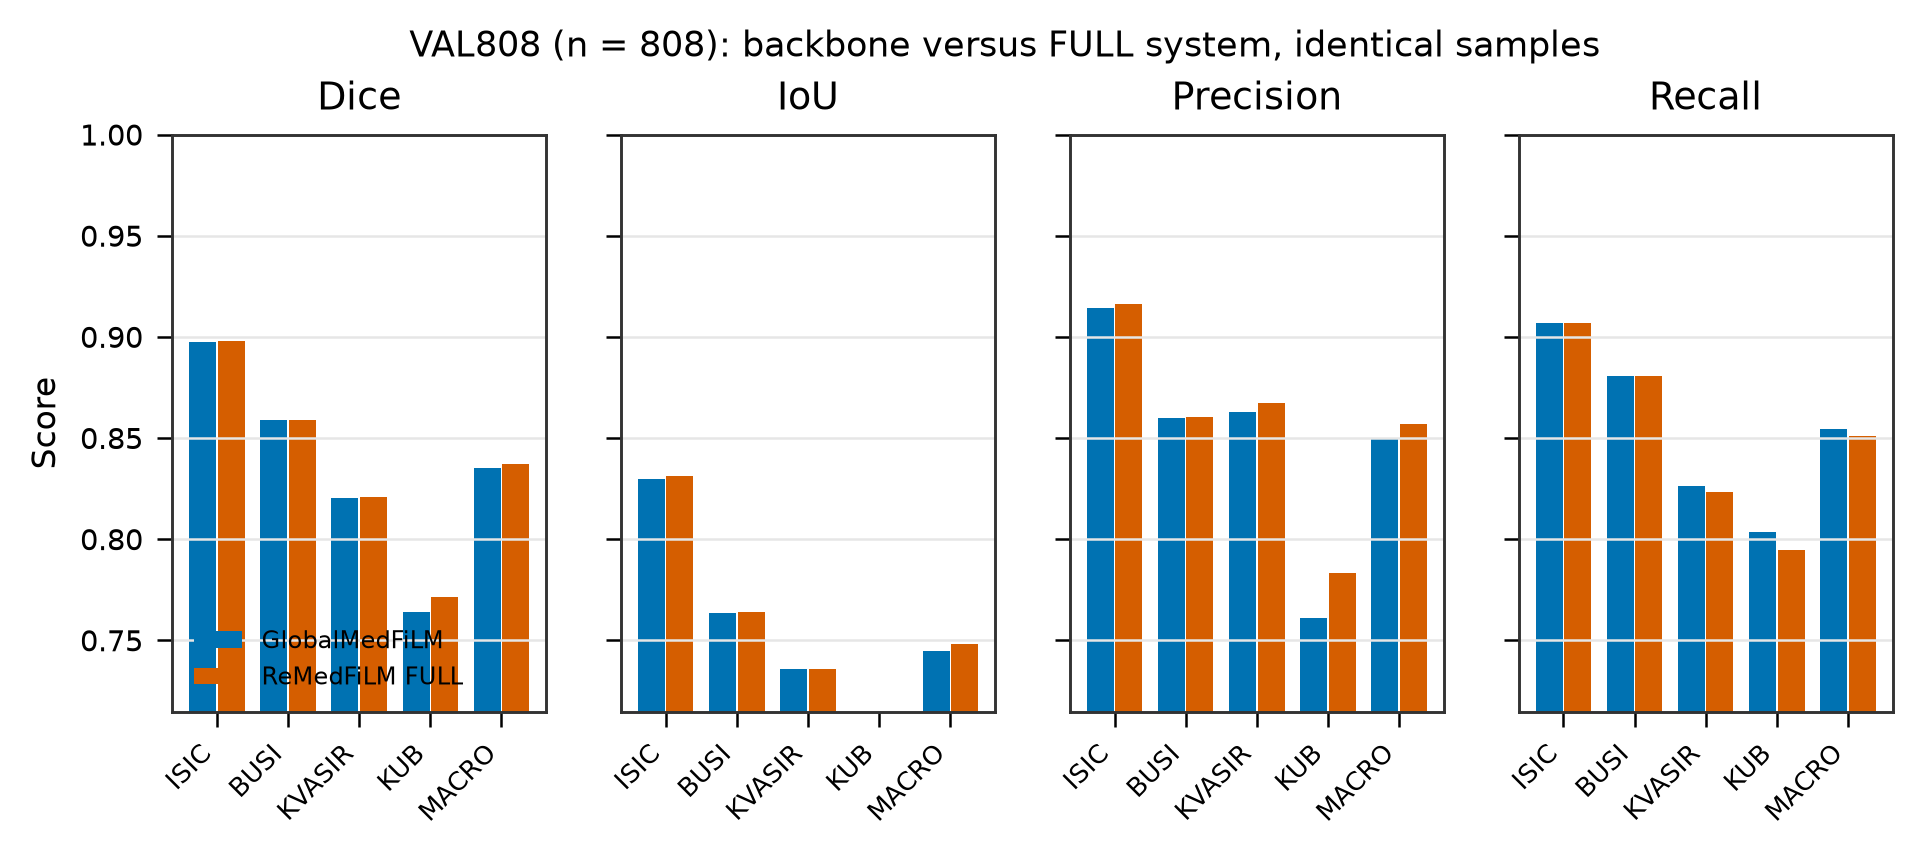

In [4]:
fig("Internal validation", "I1_domain_metric_comparison", width=780)

## 4.2 Paired effect size and confidence interval

In [5]:
paired = json.loads((TABLES / "REMEDFILM_PAIRED_DELTA.json").read_text(encoding="utf-8"))
print("point :", f"{paired['point']:+.8f}")
print("95% CI:", f"[{paired['ci_low']:+.8f}, {paired['ci_high']:+.8f}]")
print("B     :", paired["n_boot"], "| seed", paired["seed"])
print("frozen Phase 27 cross-check diff:",
      f"{abs(paired['point'] - paired['cross_check_phase27_macro_point']):.2e}")

point : +0.00220997
95% CI: [+0.00114769, +0.00329205]
B     : 10000 | seed 20261027
frozen Phase 27 cross-check diff: 1.77e-07


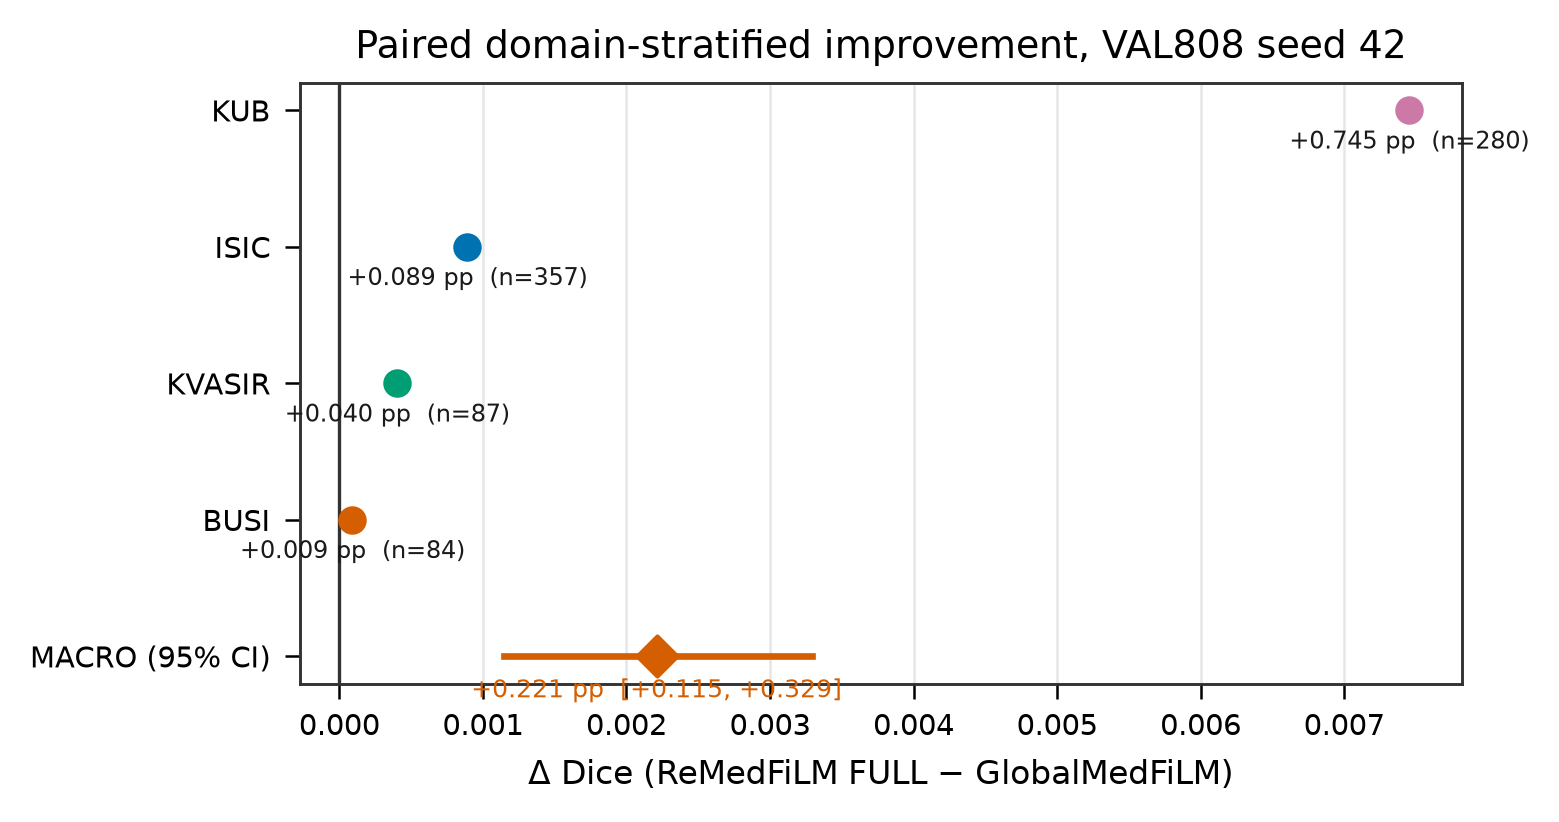

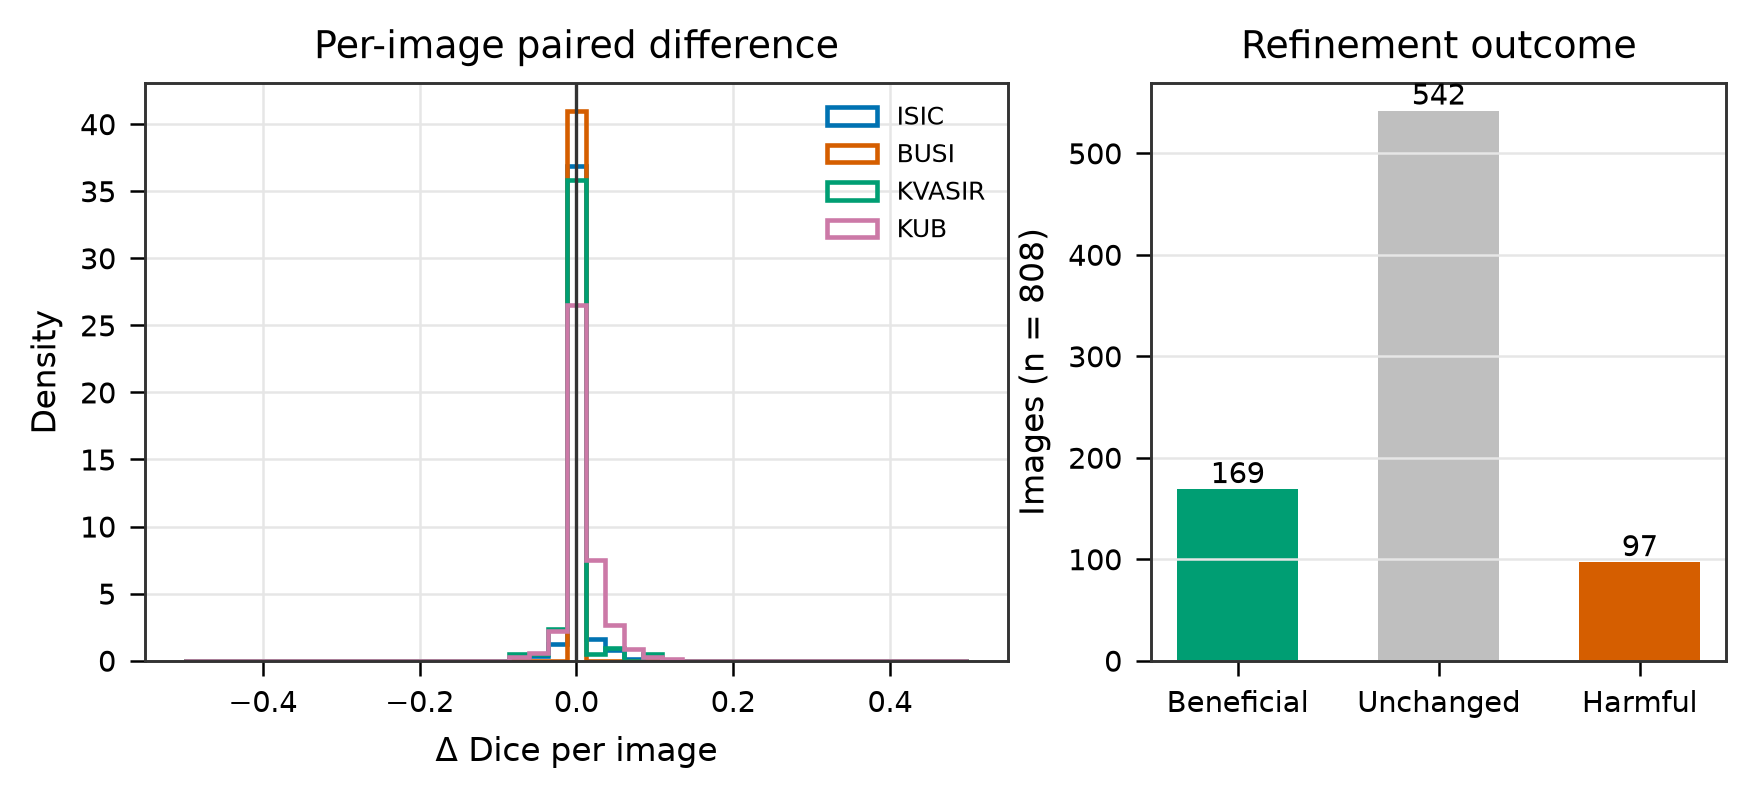

In [6]:
fig("Internal validation", "I2_paired_delta_forest", width=680)
fig("Internal validation", "I3_paired_delta_distribution", width=760)

## 4.3 Harmful, beneficial and unchanged refinements

In [7]:
ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
print("beneficial:", int((ps.delta_dice > 1e-12).sum()),
      "| unchanged:", int((ps.delta_dice.abs() <= 1e-12).sum()),
      "| harmful:", int((ps.delta_dice < -1e-12).sum()))
print()
print("routing:")
print(ps.branch.value_counts().to_string())

beneficial: 169 | unchanged: 542 | harmful: 97

routing:
branch
SKIP_GLOBAL            529
EXECUTE_THEN_ACCEPT    266
EXECUTE_THEN_REJECT     13


In [8]:
# Harm concentration among executed cases only.
ex = ps[ps.router_decision == "EXECUTE"]
print("executed cases:", len(ex))
print("harmful among executed:", int((ex.delta_dice < -1e-12).sum()),
      f"({(ex.delta_dice < -1e-12).mean():.2%})")
print("mean delta among executed:", f"{ex.delta_dice.mean():+.6f}")

executed cases: 279
harmful among executed: 97 (34.77%)
mean delta among executed: +0.008775


## 4.4 Boundary error

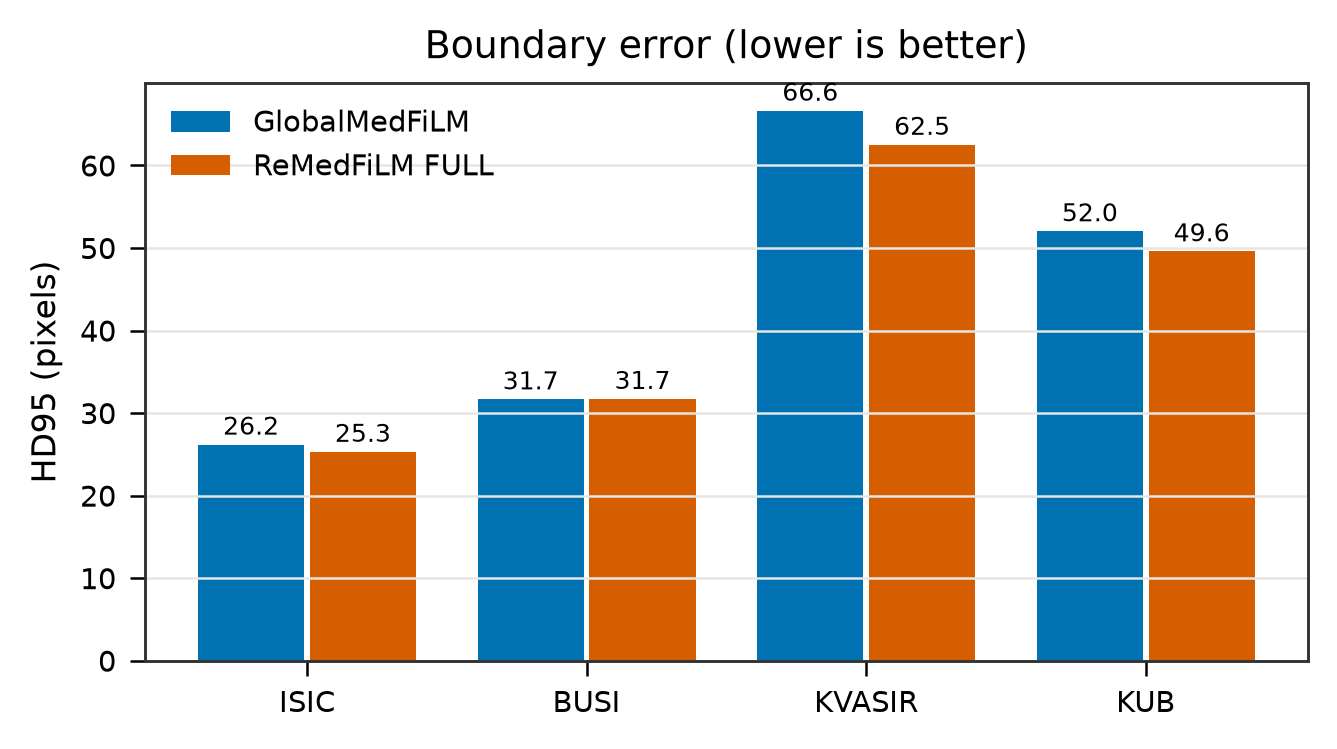

In [9]:
fig("Internal validation", "I4_hd95_comparison", width=560)

## 4.5 Subgroups inside KUB

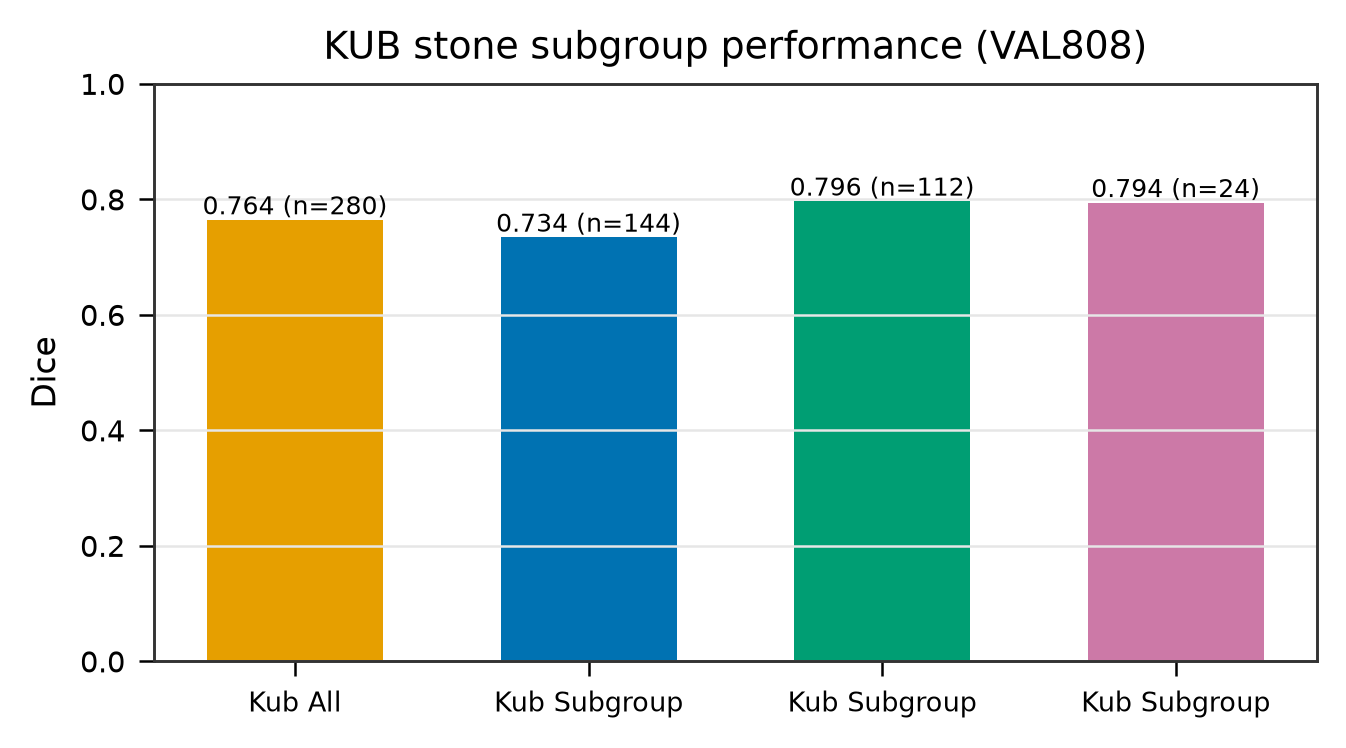

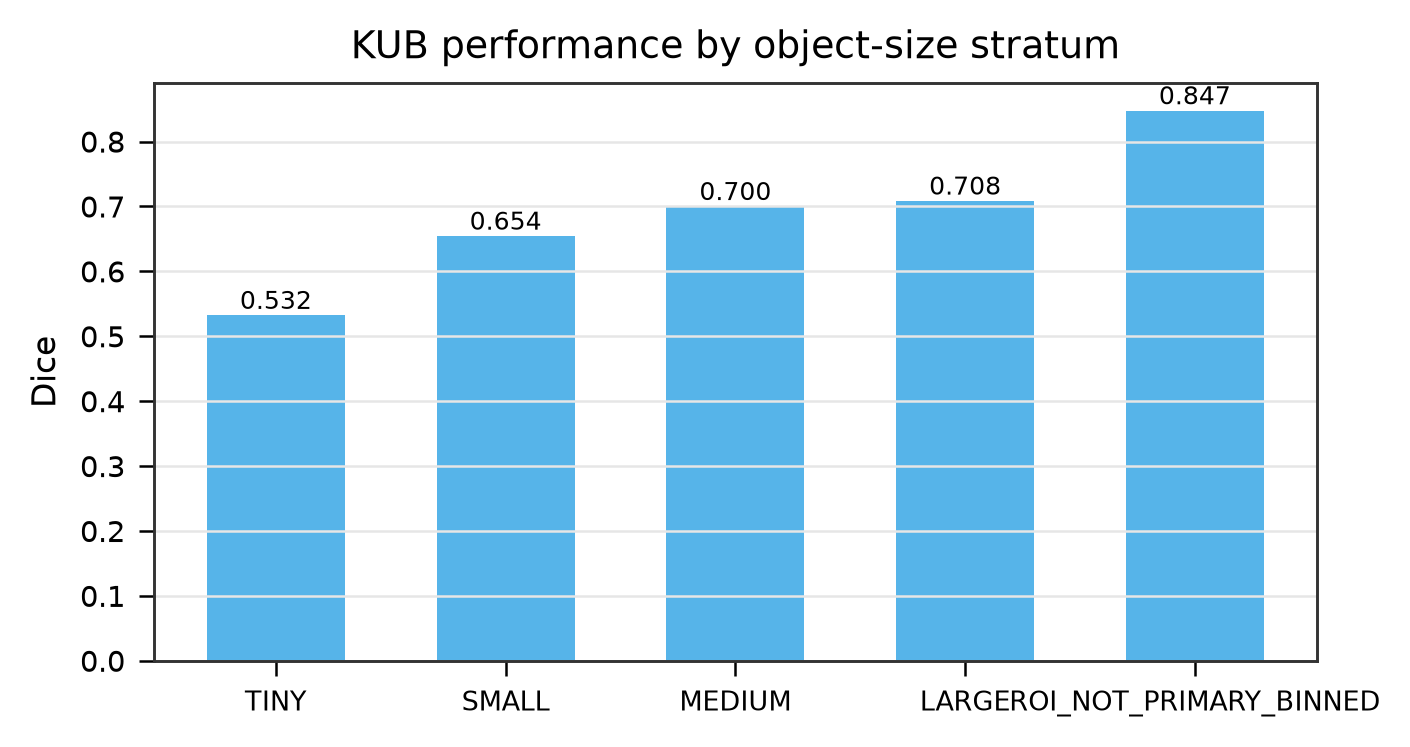

In [10]:
fig("Internal validation", "SG1_kub_stone_subgroups", width=580)
fig("Internal validation", "SG2_kub_size_stratification", width=580)

## 4.6 What this notebook does **not** establish

The comparison is backbone-versus-assembly on one frozen checkpoint. It is a
**paired preservation** result, not a controlled component attribution — that
would require the C2 study, which is not established. See
`PENDING_CONTROLLED_EXPERIMENTS.md`.

In [11]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
